In [1]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration of APL pi pulses on two qubits

In [2]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

In [3]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

desired_duration = 128 # dt, apl pulses

granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 128)

In [4]:
pico_a = ps.from_csv(
    "../pico-pulses/apl-pulses/x_gates.csv" # gates with 2 pi offset
)
# pico_a = ps.from_csv(
#     "../pico-pulses/saved-pulses-2024-05-01/single_qubit_gateset.csv" # gates without 2 pi offset
# )
pico_gates = {key: row for key, row in zip(["x1", "x2"], pico_a)}

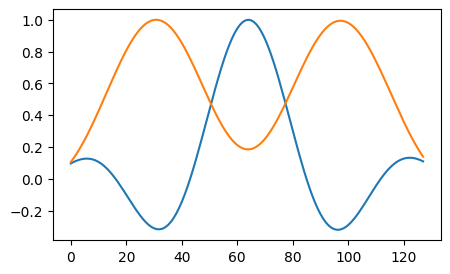

In [5]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

In [6]:
np.trapz(pico_gates["x1"], dx=dt), np.trapz(pico_gates["x2"], dx=dt)

(8.810458407220983, 38.473189703029895)

## Rough calibration

In [7]:
from qiskit.circuit import Parameter
import qiskit.pulse as pulse
from qiskit_experiments.calibration_management.calibrations import Calibrations
from qiskit_experiments.library.calibration import RoughAmplitudeCal

In [8]:
def add_sched(cals, backend, gate_key, qubit) -> Calibrations:
    amp = Parameter("amp")
    channel = pulse.DriveChannel(qubit)

    with qk.pulse.build(name="x", backend=backend) as x90p:
        signal = pico_gates[gate_key]
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        param_gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "x", amp=amp
        )
        qk.pulse.play(param_gate, channel)
    print(f"Max amplitude: {np.max(np.abs(signal_samples))}")
    cals.add_schedule(x90p, (qubit,))

In [9]:
cals = Calibrations.from_backend(backend)
add_sched(cals, backend, "x1", 0)
add_sched(cals, backend, "x2", 1)

Max amplitude: 1.0
Max amplitude: 1.0


In [ ]:
# set some starting value for amplitude
cals.add_parameter_value(0.5, Parameter("amp"), (0,), "x")
cals.add_parameter_value(0.5, Parameter("amp"), (1,), "x") 

In [ ]:
drive_amps_1 = np.linspace(-1, 1, 51)
rabi_x1 = RoughAmplitudeCal(
    physical_qubits=(0,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_1, 
    target_angle=np.pi, 
)

In [ ]:
drive_amps_2 = np.linspace(-0.5, 0.5, 51)
rabi_x2 = RoughAmplitudeCal(
    physical_qubits=(1,), 
    calibrations=cals, 
    backend=backend, 
    amplitudes=drive_amps_2, 
    target_angle=3 * np.pi, # 3 pi if working with offset
)

In [ ]:
rabi_x1_data = rabi_x1.run()
rabi_x2_data = rabi_x2.run()

In [14]:
rabi_x1_data.job_ids, rabi_x2_data.job_ids

(['cssgfdxvkv50008gbmq0'], ['cssgff5sgar0008bvbe0'])

In [65]:
rabi_x1_data.job_status(), rabi_x2_data.job_status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

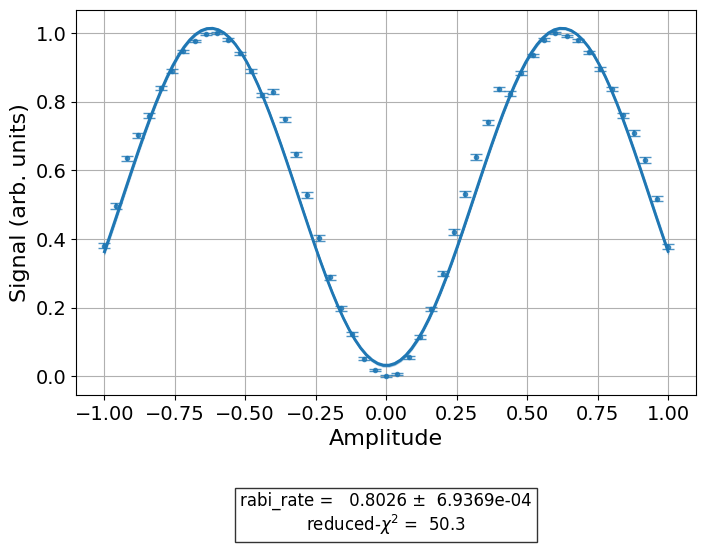

In [66]:
rabi_x1_data.block_for_results()
rabi_x1_data.figure(0)

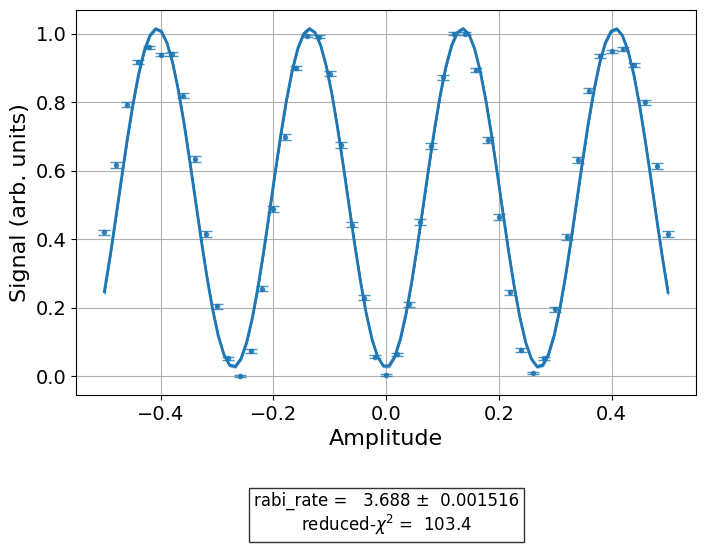

In [67]:
rabi_x2_data.block_for_results()
rabi_x2_data.figure(0)

In [68]:
from qiskit_experiments.calibration_management.update_library import BaseUpdater

def update_param(exp, exp_data):
    result_index = exp.experiment_options.result_index
    rate = 2 * np.pi * BaseUpdater.get_value(exp_data, exp.__outcome__, result_index)

    angle, _, _, prev_amp = exp_data.metadata["angles_schedules"][0]
    value = np.round(angle / rate, decimals=8) * prev_amp / np.abs(prev_amp)
    print(f"Target angle: {angle}")
    print(f"New amplitude: {value}")
    return value

In [69]:
rough_x1_amp = update_param(rabi_x1, rabi_x1_data)

Target angle: 3.141592653589793
New amplitude: 0.62300177


In [70]:
rough_x2_amp = update_param(rabi_x2, rabi_x2_data)

Target angle: 9.42477796076938
New amplitude: 0.4067519


In [71]:
cals.add_parameter_value(rough_x1_amp, Parameter("amp"), (0,), "x")
cals.add_parameter_value(rough_x2_amp, Parameter("amp"), (1,), "x")

amp
amp
amp
amp


In [72]:
rough_x1 = cals.get_schedule("x", (0,))
rough_x2 = cals.get_schedule("x", (1,))
rough_x1, rough_x2

amp
amp


(ScheduleBlock(Play(x(duration=128, amp=0.62300177, angle=0), DriveChannel(0)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=128, amp=0.4067519, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()))

In [73]:
np.trapz(rough_x1.instructions[0][1].pulse.get_waveform().samples, dx=dt), np.trapz(rough_x2.instructions[0][1].pulse.get_waveform().samples, dx=dt)

((5.48672617759784+0j), (15.648541225485467+0j))

## Fine calibration 

In [157]:
current_x1 = cals.get_schedule("x", (0,))
current_x2 = cals.get_schedule("x", (1,))
current_x1, current_x2

amp
amp


(ScheduleBlock(Play(x(duration=128, amp=0.6135050255, angle=0), DriveChannel(0)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=128, amp=0.4090401829, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()))

In [158]:
def get_fine_circuit(length: int, qubit: int, num_qubits: int, schedule):
    qc = qk.QuantumCircuit(num_qubits, 1)
    qc.sx(qubit)
    for _ in range(length):
        qc.x(qubit)
    qc.measure(qubit, 0)

    x_gate = qk.circuit.library.XGate()
    qc.add_calibration(x_gate, (qubit,), schedule)

    return qc

In [159]:
num_qubits = backend.num_qubits

In [160]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")
sampler = Sampler(backend=backend, session=session)

Session id: csstgwbah4b0008cw5rg


In [161]:
lengths = range(0, 20)
x1_testing = [get_fine_circuit(l, 0, num_qubits, current_x1) for l in lengths]
x2_testing = [get_fine_circuit(l, 1, num_qubits, current_x2) for l in lengths]

In [162]:
x1_testing_job = sampler.run(x1_testing, shots=1024)
x2_testing_job = sampler.run(x2_testing, shots=1024)

In [163]:
x1_testing_job.job_id(), x2_testing_job.job_id()

('csstgxvzsqjg008t91eg', 'csstgy3sgar0008bw680')

In [181]:
x1_testing_job.status(), x2_testing_job.status()

('DONE', 'DONE')

In [182]:
x1_results = x1_testing_job.result()
x1_counts = []
for result in x1_results:
    x1_counts.append(result.data.c.get_counts()['1'] / 1024)

x2_results = x2_testing_job.result()
x2_counts = []
for result in x2_results:
    x2_counts.append(result.data.c.get_counts()['1'] / 1024)

In [183]:
def get_d_theta(counts, estimate=0.1, plot=True):
    def fit_function(x_values, y_values, function, init_params):
        fitparams, conv = curve_fit(function, x_values, y_values, init_params)
        y_fit = function(x_values, *fitparams)
        return fitparams, y_fit, conv

    starting_params = [estimate]
    fit_params, y_fit, _ = fit_function(
        lengths,
        counts,
        lambda x, d_theta: (
            (1 / 2) * np.cos((d_theta + np.pi) * x - (np.pi / 2)) + 0.5
        ),
        starting_params,
    )

    if plot:
        fine_fit = [(1 / 2) * np.cos((fit_params[0] + np.pi) * x - (np.pi / 2)) + 0.5 for x in np.linspace(0, lengths[-1], 200)]
        plt.scatter(lengths, counts, marker="x", color="black")
        plt.plot(np.linspace(0, lengths[-1], 200), fine_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1")
        plt.title("Fine amplitude calibration")
        plt.show()

    d_theta = fit_params[0]  # get over/under rotation
    return d_theta

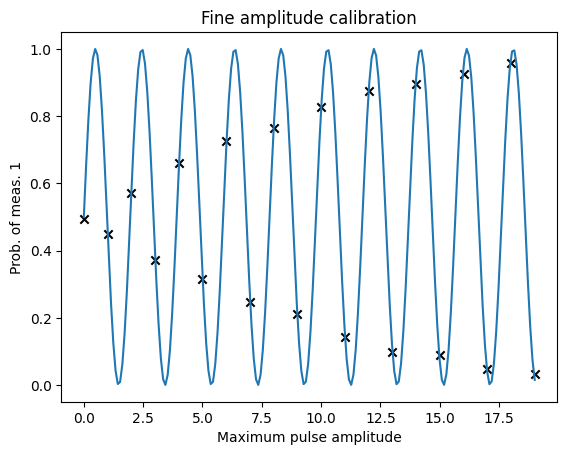

In [184]:
d_theta_x1 = get_d_theta(x1_counts, 0.1)

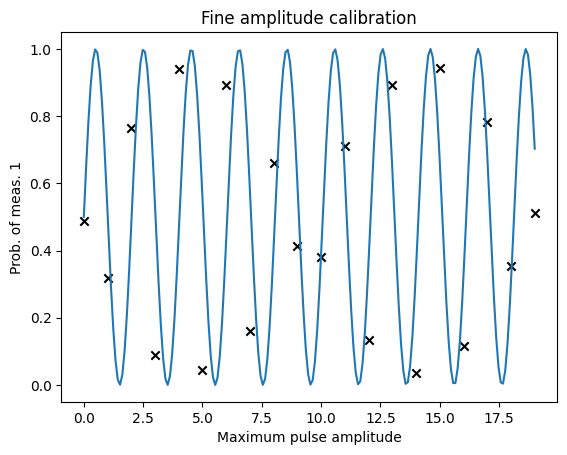

In [185]:
d_theta_x2 = get_d_theta(x2_counts, 0.1)

In [186]:
scale_x1 = (np.pi) / (np.pi + d_theta_x1)
scale_x2 = (np.pi) / (np.pi + d_theta_x2)
scale_x1, scale_x2

(0.9783451494808556, 1.0070551224552737)

In [187]:
fine_x1_amp = rough_x1_amp * scale_x1
fine_x2_amp = rough_x2_amp * scale_x2
fine_x1_amp, fine_x2_amp

(0.6095107597974876, 0.40962158446341523)

In [188]:
cals.add_parameter_value(fine_x1_amp, Parameter("amp"), (0,), "x")
cals.add_parameter_value(fine_x2_amp, Parameter("amp"), (1,), "x")

amp
amp
amp
amp


## Dynamical decoupling sequences

In [189]:
final_x1 = cals.get_schedule("x", (0,))
final_x2 = cals.get_schedule("x", (1,))
final_x1, final_x2

amp
amp


(ScheduleBlock(Play(x(duration=128, amp=0.6095107598, angle=0), DriveChannel(0)), name="x", transform=AlignLeft()),
 ScheduleBlock(Play(x(duration=128, amp=0.4096215845, angle=0), DriveChannel(1)), name="x", transform=AlignLeft()))

In [190]:
def xyxy_sequence(repetitions: int, num_qubits: int, q0: int, q1: int, schedules = None):
    qc = qk.QuantumCircuit(num_qubits, 2)
    qc.sx(q0)
    qc.sx(q1)
    for _ in range(repetitions):
        qc.x(q0)
        qc.y(q0)
        qc.x(q0)
        qc.y(q0)
        qc.x(q1)
        qc.y(q1)
        qc.x(q1)
        qc.y(q1)
    qc.sx(q0)
    qc.sx(q1)
    qc.measure(q0, 0)
    qc.measure(q1, 1)

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [191]:
num_qubits = backend.num_qubits
num_qubits

127

In [192]:
example = xyxy_sequence(1, num_qubits, 0, 1)
example.draw(idle_wires=False)

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐┌─┐   
q_0: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├┤M├───
     ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤└╥┘┌─┐
q_1: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─╫─┤M├
     └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘ ║ └╥┘
c: 2/═══════════════════════════════════════════════════╩══╩═
                                                        0  1

In [193]:
lengths = list(range(1, 401, 4))
dd_circuits_robust = [xyxy_sequence(i, num_qubits, 0, 1, [final_x1, final_x2]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, num_qubits, 0, 1) for i in lengths]

In [ ]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [201]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id()

('cst1xansgar0008bwxf0', 'cst1xbdjkdzg008897m0')

In [248]:
dd_jobs_robust.status(), dd_jobs_default.status()

('DONE', 'DONE')

In [250]:
dd_jobs_robust = service.job("cst1xansgar0008bwxf0")
dd_jobs_default = service.job("cst1xbdjkdzg008897m0")

In [266]:
robust_results = dd_jobs_robust.result()
robust_counts = []
for result in robust_results:
    robust_counts.append(result.data.c.get_counts())

default_results = dd_jobs_default.result()
default_counts = []
for result in default_results:
    default_counts.append(result.data.c.get_counts())

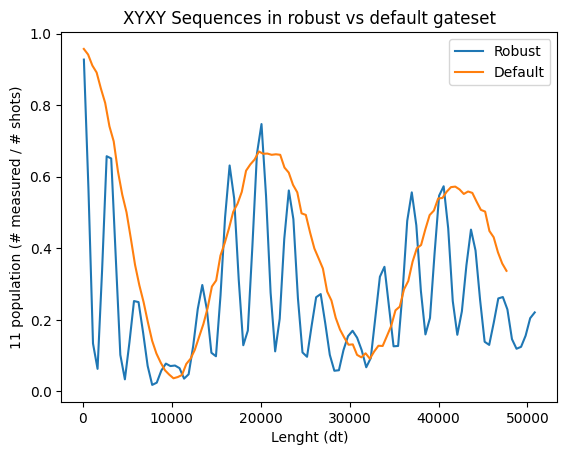

In [267]:
robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
default_11 = [count.get("11", 0) / 2048 for count in default_counts]

plt.plot([l * desired_duration for l in lengths], robust_11, label="Robust")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.xlabel("Lenght (dt)")
plt.ylabel("11 population (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

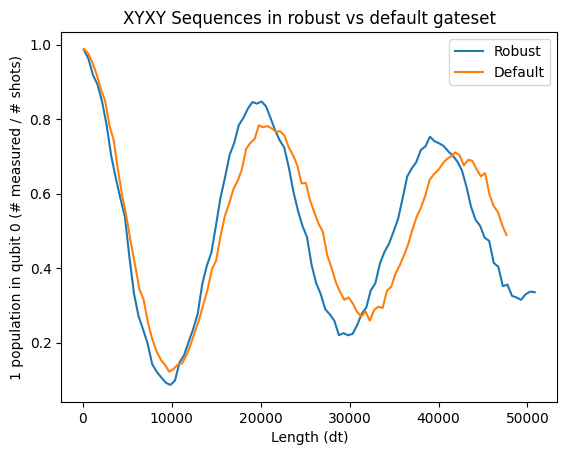

In [268]:
robust_11 = [(count.get("01", 0) + count.get("11", 0)) / 2048 for count in robust_counts]
default_11 = [(count.get("01", 0) + count.get("11", 0))  / 2048 for count in default_counts]

plt.plot([l * desired_duration for l in lengths], robust_11, label="Robust")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("1 population in qubit 0 (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

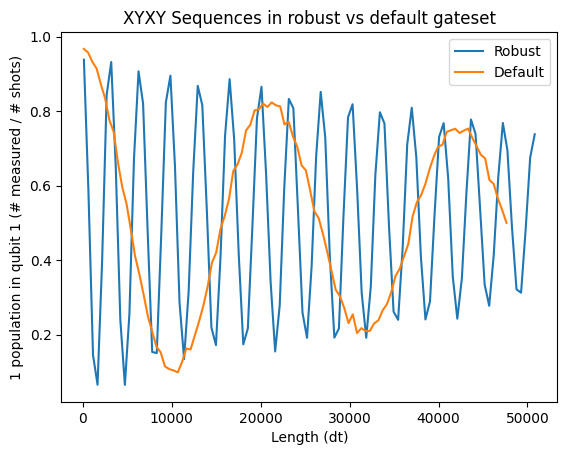

In [269]:
robust_11 = [(count.get("10", 0) + count.get("11", 0)) / 2048 for count in robust_counts]
default_11 = [(count.get("10", 0) + count.get("11", 0))  / 2048 for count in default_counts]

plt.plot([l * desired_duration for l in lengths], robust_11, label="Robust")
plt.plot([l * 120 for l in lengths], default_11, label="Default")
plt.xlabel("Length (dt)")
plt.ylabel("1 population in qubit 1 (# measured / # shots)")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()